# 🚗 Car Auction Risk Prediction: EDA & Feature Engineering

This notebook explores the "Don't Get Kicked!" car auction dataset. The goal is to predict whether a purchased vehicle will be a "BadBuy" (a lemon that results in financial loss for the auction house). 

Because this is a highly imbalanced classification problem, we will focus on understanding the data distributions and justifying our advanced feature engineering strategy—specifically, **Frequency Encoding** for high-cardinality categoricals.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

data_path = Path('../data/raw/training.csv')
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (72983, 34)


,RefId,IsBadBuy,PurchDate,Auction,VehYear,VehicleAge,Make,Model,Trim,SubModel,...,MMRCurrentRetailAveragePrice,MMRCurrentRetailCleanPrice,PRIMEUNIT,AUCGUART,BYRNO,VNZIP1,VNST,VehBCost,IsOnlineSale,WarrantyCost
0,1,0,12/7/2009,ADESA,2006,3,MAZDA,MAZDA3,i,4D SEDAN I,...,11597.0,12409.0,NaN,NaN,21973,33619,FL,7100.0,0,1113
1,2,0,12/7/2009,ADESA,2004,5,DODGE,1500 RAM PICKUP 2WD,ST,QUAD CAB 4.7L SLT,...,11374.0,12791.0,NaN,NaN,19638,33619,FL,7600.0,0,1053
2,3,0,12/7/2009,ADESA,2005,4,DODGE,STRATUS V6,SXT,4D SEDAN SXT FFV,...,7146.0,8702.0,NaN,NaN,19638,33619,FL,4900.0,0,1389
3,4,0,12/7/2009,ADESA,2004,5,DODGE,NEON,SXT,4D SEDAN,...,4375.0,5518.0,NaN,NaN,19638,33619,FL,4100.0,0,630
4,5,0,12/7/2009,ADESA,2005,4,FORD,FOCUS,ZX3,2D COUPE ZX3,...,6739.0,7911.0,NaN,NaN,19638,33619,FL,4000.0,0,1020


## 1. The Business Problem & Class Imbalance

Most cars are good deals. BadBuys are the exception (~11%).
If we use Accuracy, a dummy model predicting "GoodBuy" always gets ~89% --> completely useless.

Instead, we optimize for Gini (from ROC-AUC). It measures how well the model ranks high-risk cars above low-risk ones, regardless of the threshold.

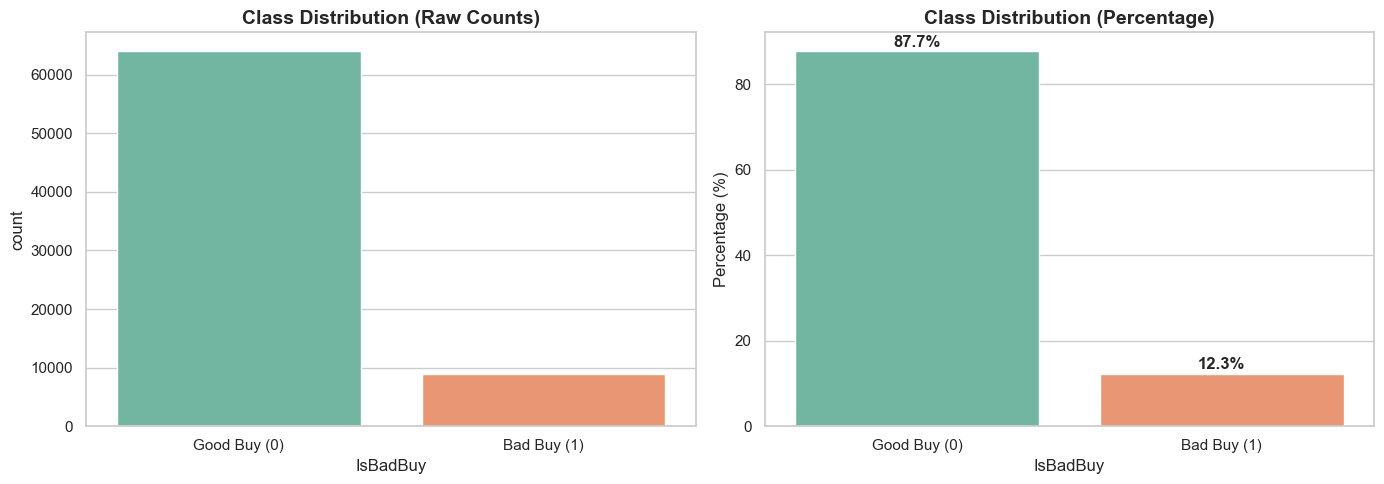

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Raw Counts
sns.countplot(data=df, x='IsBadBuy', hue='IsBadBuy', palette='Set2', legend=False, ax=ax[0])
ax[0].set_title('Class Distribution (Raw Counts)', fontsize=14, fontweight='bold')
ax[0].set_xlabel('IsBadBuy')
ax[0].set_xticks([0, 1], ['Good Buy (0)', 'Bad Buy (1)']) # Fixes UserWarning

# 2. Percentages
counts = df['IsBadBuy'].value_counts(normalize=True) * 100
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette='Set2', legend=False, ax=ax[1]) # Fixes FutureWarning
ax[1].set_title('Class Distribution (Percentage)', fontsize=14, fontweight='bold')
ax[1].set_ylabel('Percentage (%)')
ax[1].set_xticks([0, 1], ['Good Buy (0)', 'Bad Buy (1)']) # Fixes UserWarning

# Add percentage labels
for i, v in enumerate(counts.values):
    ax[1].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

## 2. The Cardinality Challenge

The dataset contains several categorical features like `Make`, `Model`, and `SubModel`. If we use standard **One-Hot Encoding (OHE)** on these features, we will create thousands of sparse, binary columns. This leads to the **curse of dimensionality**, causing linear models to overfit and tree-based models to become computationally expensive.

Let's look at the cardinality (number of unique values) for our categorical features.

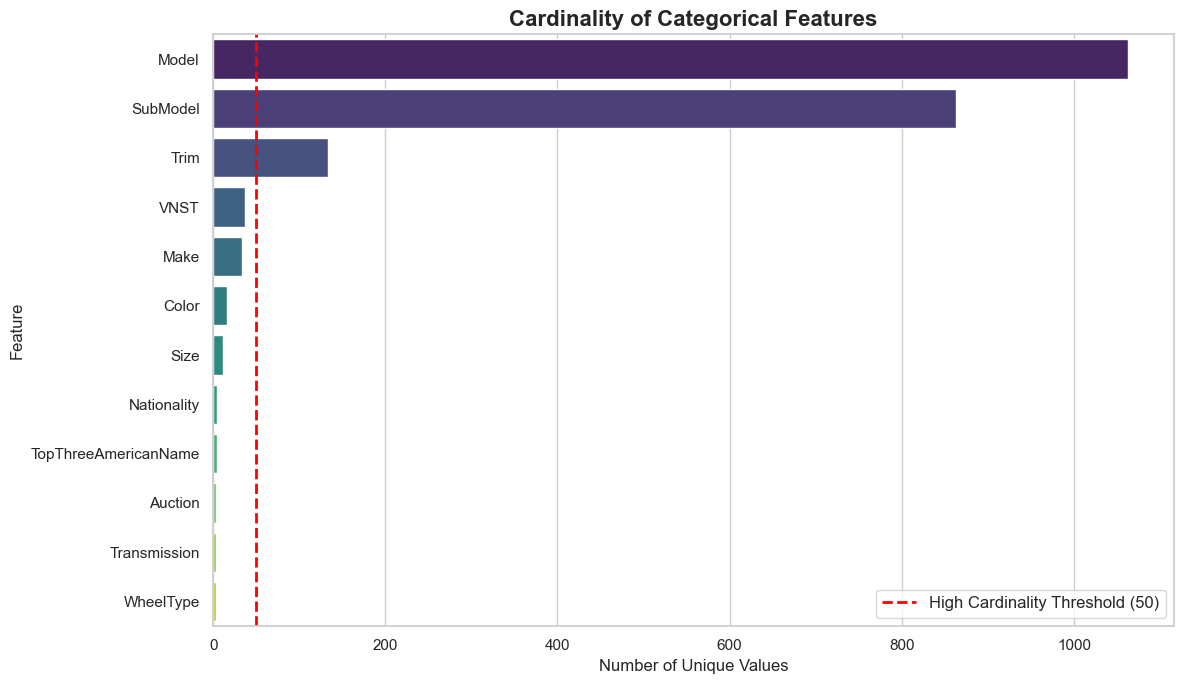

Features with > 50 unique values (High Cardinality):
['Model', 'SubModel', 'Trim']


In [8]:
# Identify categorical columns, excluding IDs, dates, and the target
exclude_cols = ['RefId', 'PRIMEUNIT', 'AUCGUART', 'IsBadBuy', 'PurchDate', 'IsOnlineSale']
cat_cols = [col for col in df.select_dtypes(include=['object', 'category']).columns 
            if col not in exclude_cols]

# Calculate cardinality
cardinality = df[cat_cols].nunique().sort_values(ascending=False)

plt.figure(figsize=(12, 7))
sns.barplot(x=cardinality.values, y=cardinality.index, hue=cardinality.index, palette='viridis', legend=False)
plt.title('Cardinality of Categorical Features', fontsize=16, fontweight='bold')
plt.xlabel('Number of Unique Values', fontsize=12)
plt.ylabel('Feature', fontsize=12)

# Add a threshold line to separate low vs high cardinality
threshold = 50
plt.axvline(x=threshold, color='red', linestyle='--', linewidth=2, label=f'High Cardinality Threshold ({threshold})')
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

print(f"Features with > {threshold} unique values (High Cardinality):")
print(cardinality[cardinality > threshold].index.tolist())

### 💡 The Solution: Frequency Encoding
Instead of One-Hot Encoding, we apply **Frequency Encoding** to the high-cardinality features. This replaces each category with its relative frequency (proportion) in the training set. 

*   **Pros:** Prevents dimensionality explosion, preserves the statistical weight of the category, and works beautifully with linear models.
*   **Implementation:** We built a custom `FrequencyEncoder` in `src/preprocessing.py` that safely handles unseen categories in the test set without data leakage.

## 3. Num Feature Distributions

Let's see how key numerical features behave for Good Buys vs Bad Buys. Helps to understand the mechanics of a lemon.

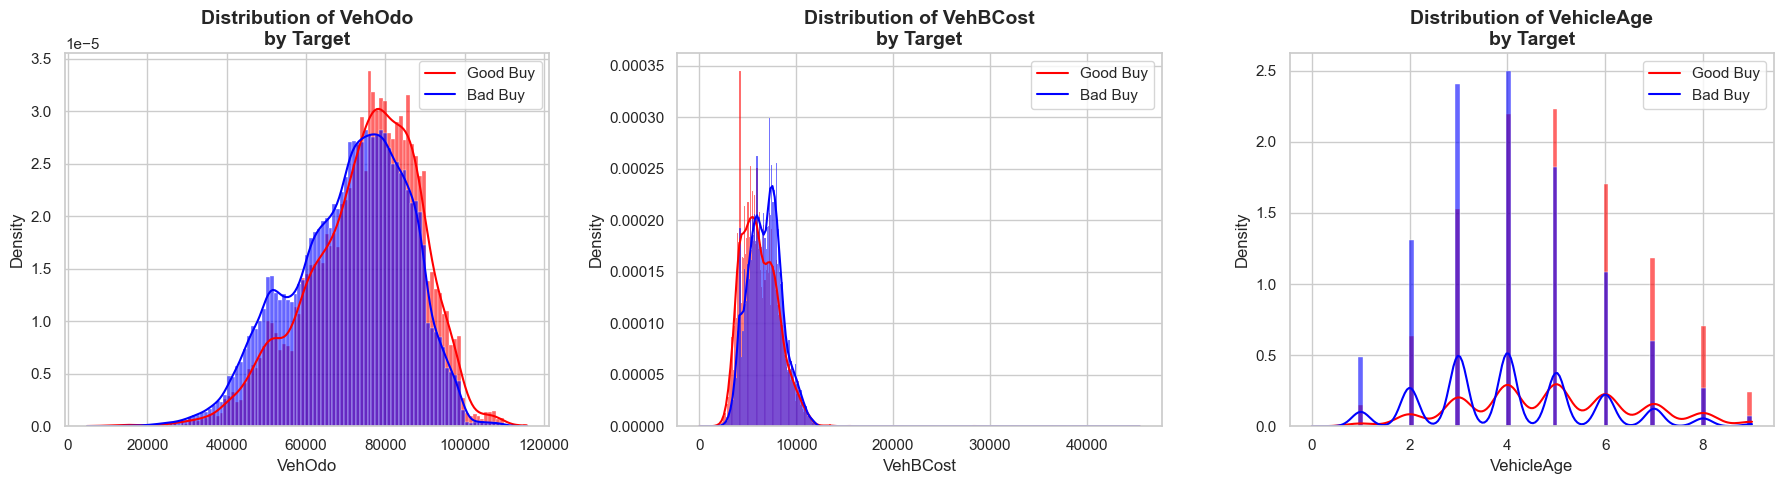

In [9]:
features_to_plot = ['VehOdo', 'VehBCost', 'VehicleAge']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(features_to_plot):
    # Using density to compare distributions fairly despite class imbalance
    sns.histplot(data=df, x=col, hue='IsBadBuy', stat='density', common_norm=False, 
                 kde=True, palette={0: 'blue', 1: 'red'}, ax=axes[i], alpha=0.6)
    axes[i].set_title(f'Distribution of {col}\nby Target', fontsize=14, fontweight='bold')
    axes[i].legend(['Good Buy', 'Bad Buy'])
    
plt.tight_layout()
plt.show()

## 4. Non-Linear Features

Linear models (like LogReg) can't automatically capture interactions (e.g. high odo is only bad if the car is also very old).

To help the model, we engineered interaction features in `src/preprocessing.py`:
- Ratios: `VehOdo / VehicleAge` (miles per year), `VehBCost / VehOdo` (price per mile).
- Smoothed group means: Bayesian-smoothed average odo grouped by `Make`. Prevents rare makes (1-2 rows) from skewing the model.

Combined with L1 regularization, the model automatically selects the best signals and ignores noise.

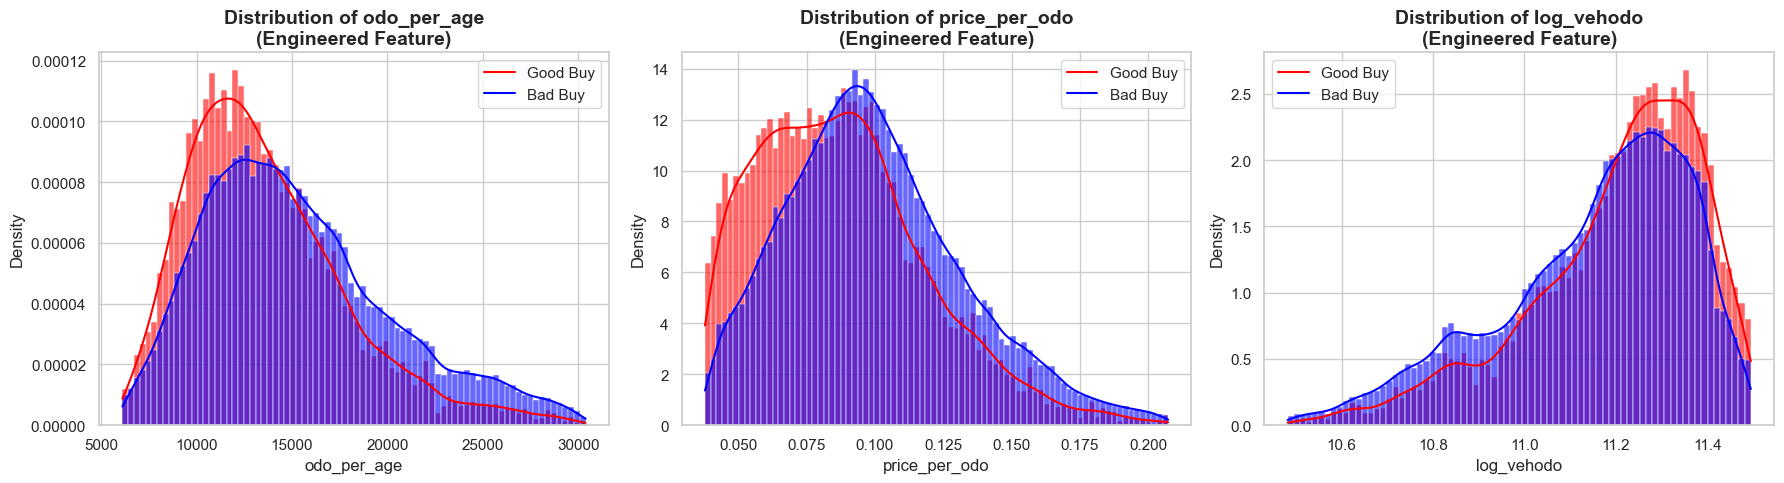

In [10]:
# Create a copy for EDA to avoid modifying the original dataframe
df_eda = df.copy()

# 1. Create Ratio Features (Adding +1 to denominators to prevent division by zero)
eps = 1.0
df_eda['odo_per_age'] = df_eda['VehOdo'] / (df_eda['VehicleAge'] + eps)
df_eda['price_per_odo'] = df_eda['VehBCost'] / (df_eda['VehOdo'] + eps)
df_eda['warranty_per_age'] = df_eda['WarrantyCost'] / (df_eda['VehicleAge'] + eps)

# 2. Create Log Transformation (helps normalize heavily skewed data like odometer)
df_eda['log_vehodo'] = np.log1p(df_eda['VehOdo'])

# Features to plot
engineered_features = ['odo_per_age', 'price_per_odo', 'log_vehodo']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(engineered_features):
    # Clip outliers for better visualization (1st to 99th percentile)
    lower = df_eda[col].quantile(0.01)
    upper = df_eda[col].quantile(0.99)
    plot_df = df_eda[(df_eda[col] >= lower) & (df_eda[col] <= upper)]

    # Plot density
    sns.histplot(data=plot_df, x=col, hue='IsBadBuy', stat='density', 
                 common_norm=False, kde=True, palette={0: 'blue', 1: 'red'}, 
                 ax=axes[i], alpha=0.6)
    
    axes[i].set_title(f'Distribution of {col}\n(Engineered Feature)', fontsize=14, fontweight='bold')
    axes[i].legend(['Good Buy', 'Bad Buy'])
    
plt.tight_layout()
plt.show()